In [12]:
%matplotlib inline

from IPython.display import Image

import qutip 
import qutip_qip.operations 
from qutip_qip.circuit import QubitCircuit, Gate, CircuitSimulator
from qutip import basis, tensor, qeye, sigmax, sigmaz
import random
import numpy as np


In [6]:
#MI ESTADO INICIAL <3
a=1
b=2
psi = (a*basis(2,0) + b*basis(2,1)).unit()
physical = [basis(2,0)]*10
state1 = tensor([psi]+physical)
state1

#np.set_printoptions(linewidth=200)
#print(state1.full().real.T)

Quantum object: dims=[[2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2], [1]], shape=(2048, 1), type='ket', dtype=Dense
Qobj data =
[[0.4472136]
 [0.       ]
 [0.       ]
 ...
 [0.       ]
 [0.       ]
 [0.       ]]

In [7]:
#MIS AUTOVECTORES INICIALES <3
state1.ptrace(0).eigenstates()

(array([0., 1.]),
 array([Quantum object: dims=[[2], [1]], shape=(2, 1), type='ket', dtype=Dense
        Qobj data =
        [[-0.89442719]
         [ 0.4472136 ]]                                                       ,
        Quantum object: dims=[[2], [1]], shape=(2, 1), type='ket', dtype=Dense
        Qobj data =
        [[0.4472136 ]
         [0.89442719]]                                                        ],
       dtype=object))

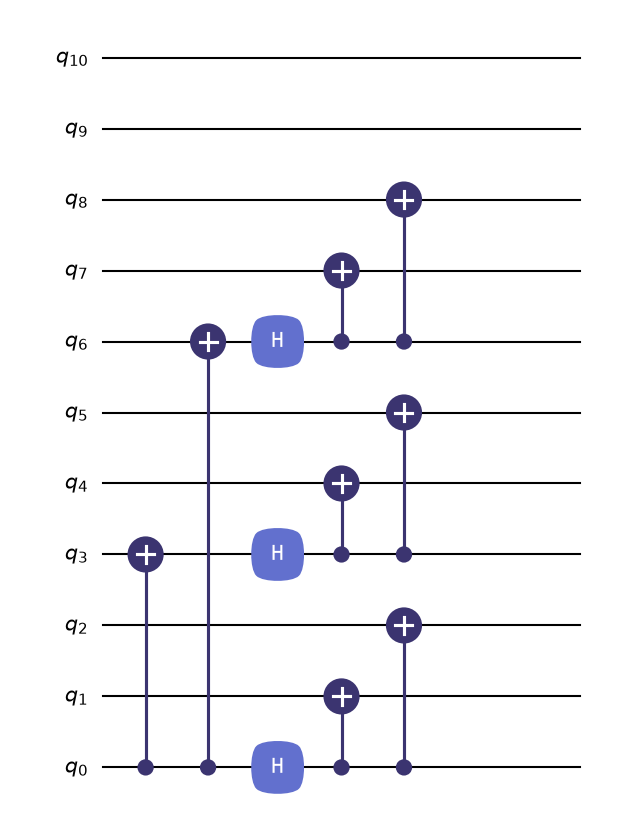

In [8]:
#CIRCUITO CODIFICADOR
qenc = QubitCircuit(11, reverse_states=False)
qenc.add_gate("CNOT", controls=[0], targets=[3])
qenc.add_gate("CNOT", controls=[0], targets=[6])

qenc.add_gate("H", targets=[0])
qenc.add_gate("H", targets=[3])
qenc.add_gate("H", targets=[6])


qenc.add_gate("CNOT", controls=[0], targets=[1])
qenc.add_gate("CNOT", controls=[0], targets=[2])
qenc.add_gate("CNOT", controls=[3], targets=[4])
qenc.add_gate("CNOT", controls=[3], targets=[5])
qenc.add_gate("CNOT", controls=[6], targets=[7])
qenc.add_gate("CNOT", controls=[6], targets=[8])

qenc


In [ ]:
#ESTADO CODIFICADO
encoded_state = qenc.run(state=state1)
encoded_state

Quantum object: dims=[[2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2], [1]], shape=(2048, 1), type='ket', dtype=Dense
Qobj data =
[[0.47434165]
 [0.        ]
 [0.        ]
 ...
 [0.        ]
 [0.        ]
 [0.        ]]

In [15]:
#GENERAR EL ESTADO CON ERROR FASE O BIT-FLIP
error_op_flip = [qeye(2)]*11
error_op_phase = [qeye(2)]*11
flip_qubit = random.randint(0,8)
phase_qubit = random.randint(0,8)
print("Bit-flipping qubit {}".format(flip_qubit))
print("Phase-flipping qubit {}".format(phase_qubit))

error_op_flip[flip_qubit] *= sigmax()
error_op_phase[phase_qubit] *= sigmaz()

#Error localizado bit-flip
i=1

errorlocalizado_flip = [qeye(2)]*11
errorlocalizado_flip[i] *= sigmax()

#Error localizado phase
j=1

errorlocalizado_phase = [qeye(2)]*11
errorlocalizado_phase[j] *= sigmaz()


#APLICA EL ERROR QUE QUIERAS: errorlocalizado_flip, errorlocalizado_phase, error_op_flip, error_op_phase
errorstate=tensor(error_op_flip) * encoded_state
#AÑADIR OTRO ERROR (diferente tipo al anterior)
errorstate=tensor(errorlocalizado_phase) * errorstate

Bit-flipping qubit 3
Phase-flipping qubit 2


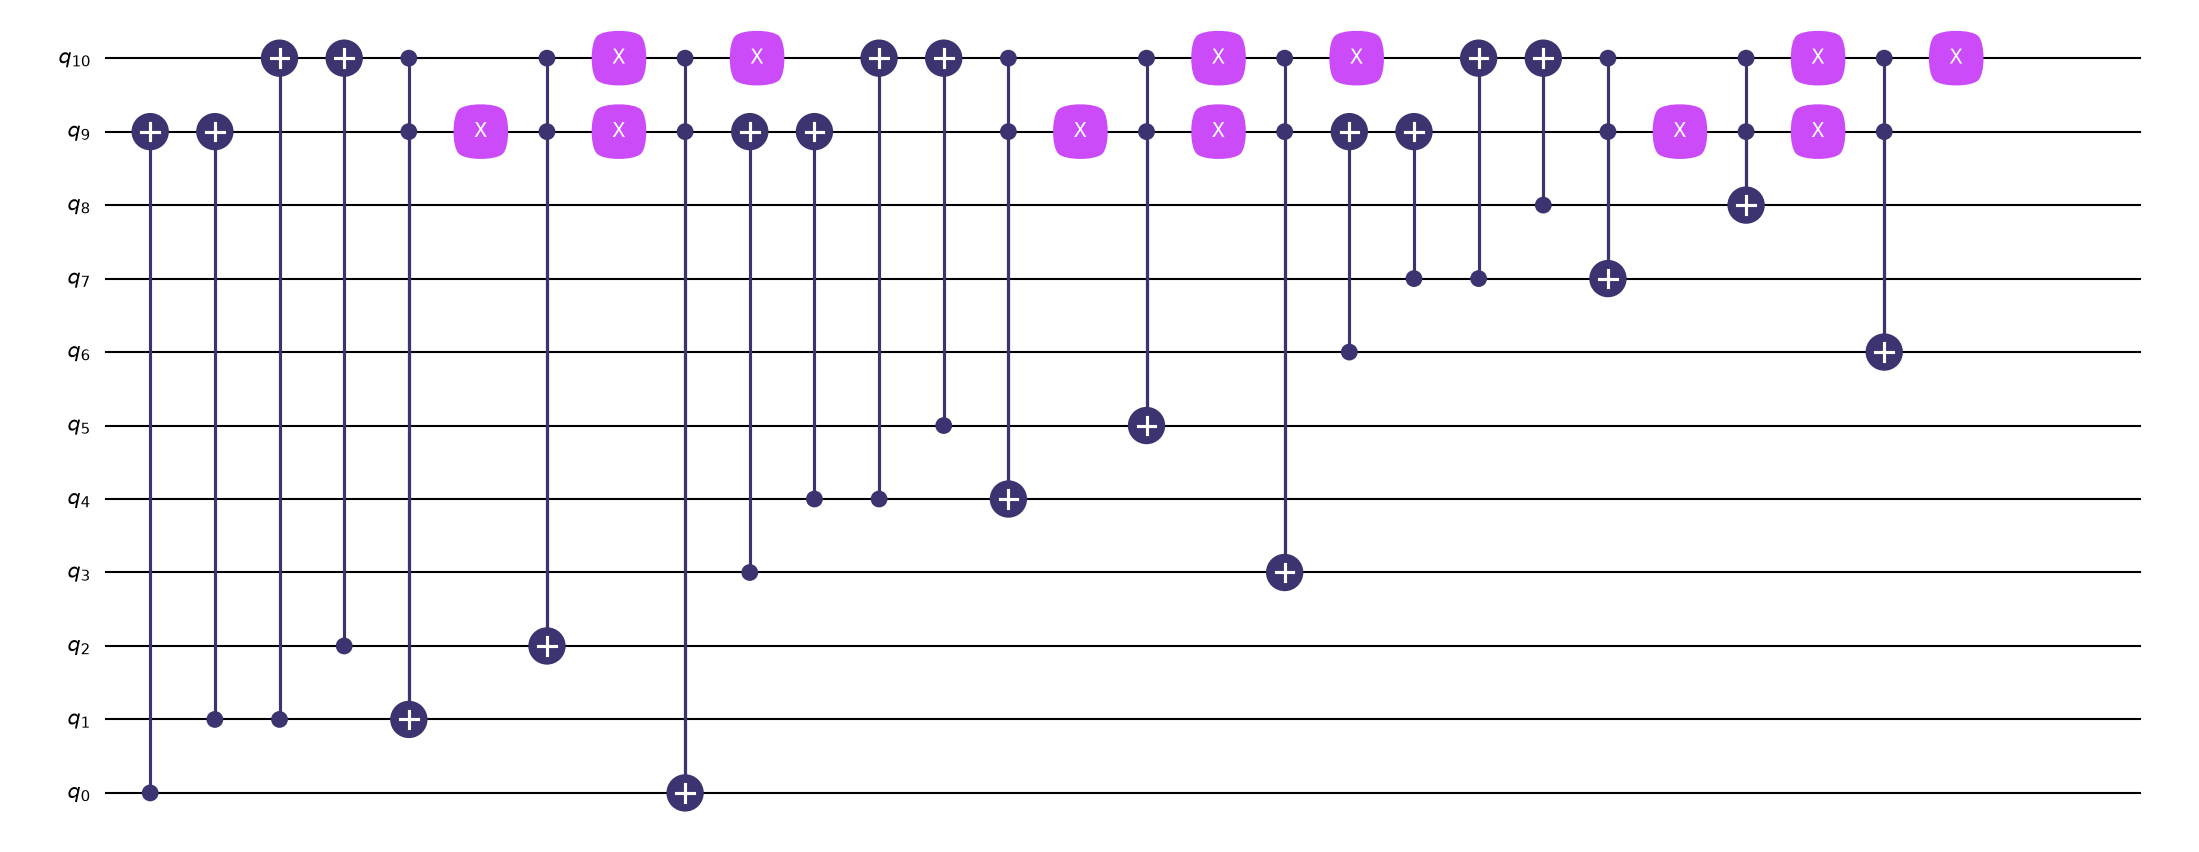

In [28]:
qcorr = QubitCircuit(11, reverse_states=False)

qcorr.add_gate("CNOT", controls=[0], targets=[9])
qcorr.add_gate("CNOT", controls=[1], targets=[9])
qcorr.add_gate("CNOT", controls=[1], targets=[10])
qcorr.add_gate("CNOT", controls=[2], targets=[10])

qcorr.add_gate("TOFFOLI", controls=[9,10], targets=[1])
qcorr.add_gate("X", targets=[9])
qcorr.add_gate("TOFFOLI", controls=[9,10], targets=[2])
qcorr.add_gate("X", targets=[9])
qcorr.add_gate("X", targets=[10])
qcorr.add_gate("TOFFOLI", controls=[9,10], targets=[0])
qcorr.add_gate("X", targets=[10])

qcorr.add_gate("CNOT", controls=[3], targets=[9])
qcorr.add_gate("CNOT", controls=[4], targets=[9])
qcorr.add_gate("CNOT", controls=[4], targets=[10])
qcorr.add_gate("CNOT", controls=[5], targets=[10])

qcorr.add_gate("TOFFOLI", controls=[9,10], targets=[4])
qcorr.add_gate("X", targets=[9])
qcorr.add_gate("TOFFOLI", controls=[9,10], targets=[5])
qcorr.add_gate("X", targets=[9])
qcorr.add_gate("X", targets=[10])
qcorr.add_gate("TOFFOLI", controls=[9,10], targets=[3])
qcorr.add_gate("X", targets=[10])

qcorr.add_gate("CNOT", controls=[6], targets=[9])
qcorr.add_gate("CNOT", controls=[7], targets=[9])
qcorr.add_gate("CNOT", controls=[7], targets=[10])
qcorr.add_gate("CNOT", controls=[8], targets=[10])

qcorr.add_gate("TOFFOLI", controls=[9,10], targets=[7])
qcorr.add_gate("X", targets=[9])
qcorr.add_gate("TOFFOLI", controls=[9,10], targets=[8])
qcorr.add_gate("X", targets=[9])
qcorr.add_gate("X", targets=[10])
qcorr.add_gate("TOFFOLI", controls=[9,10], targets=[6])
qcorr.add_gate("X", targets=[10])



qcorr

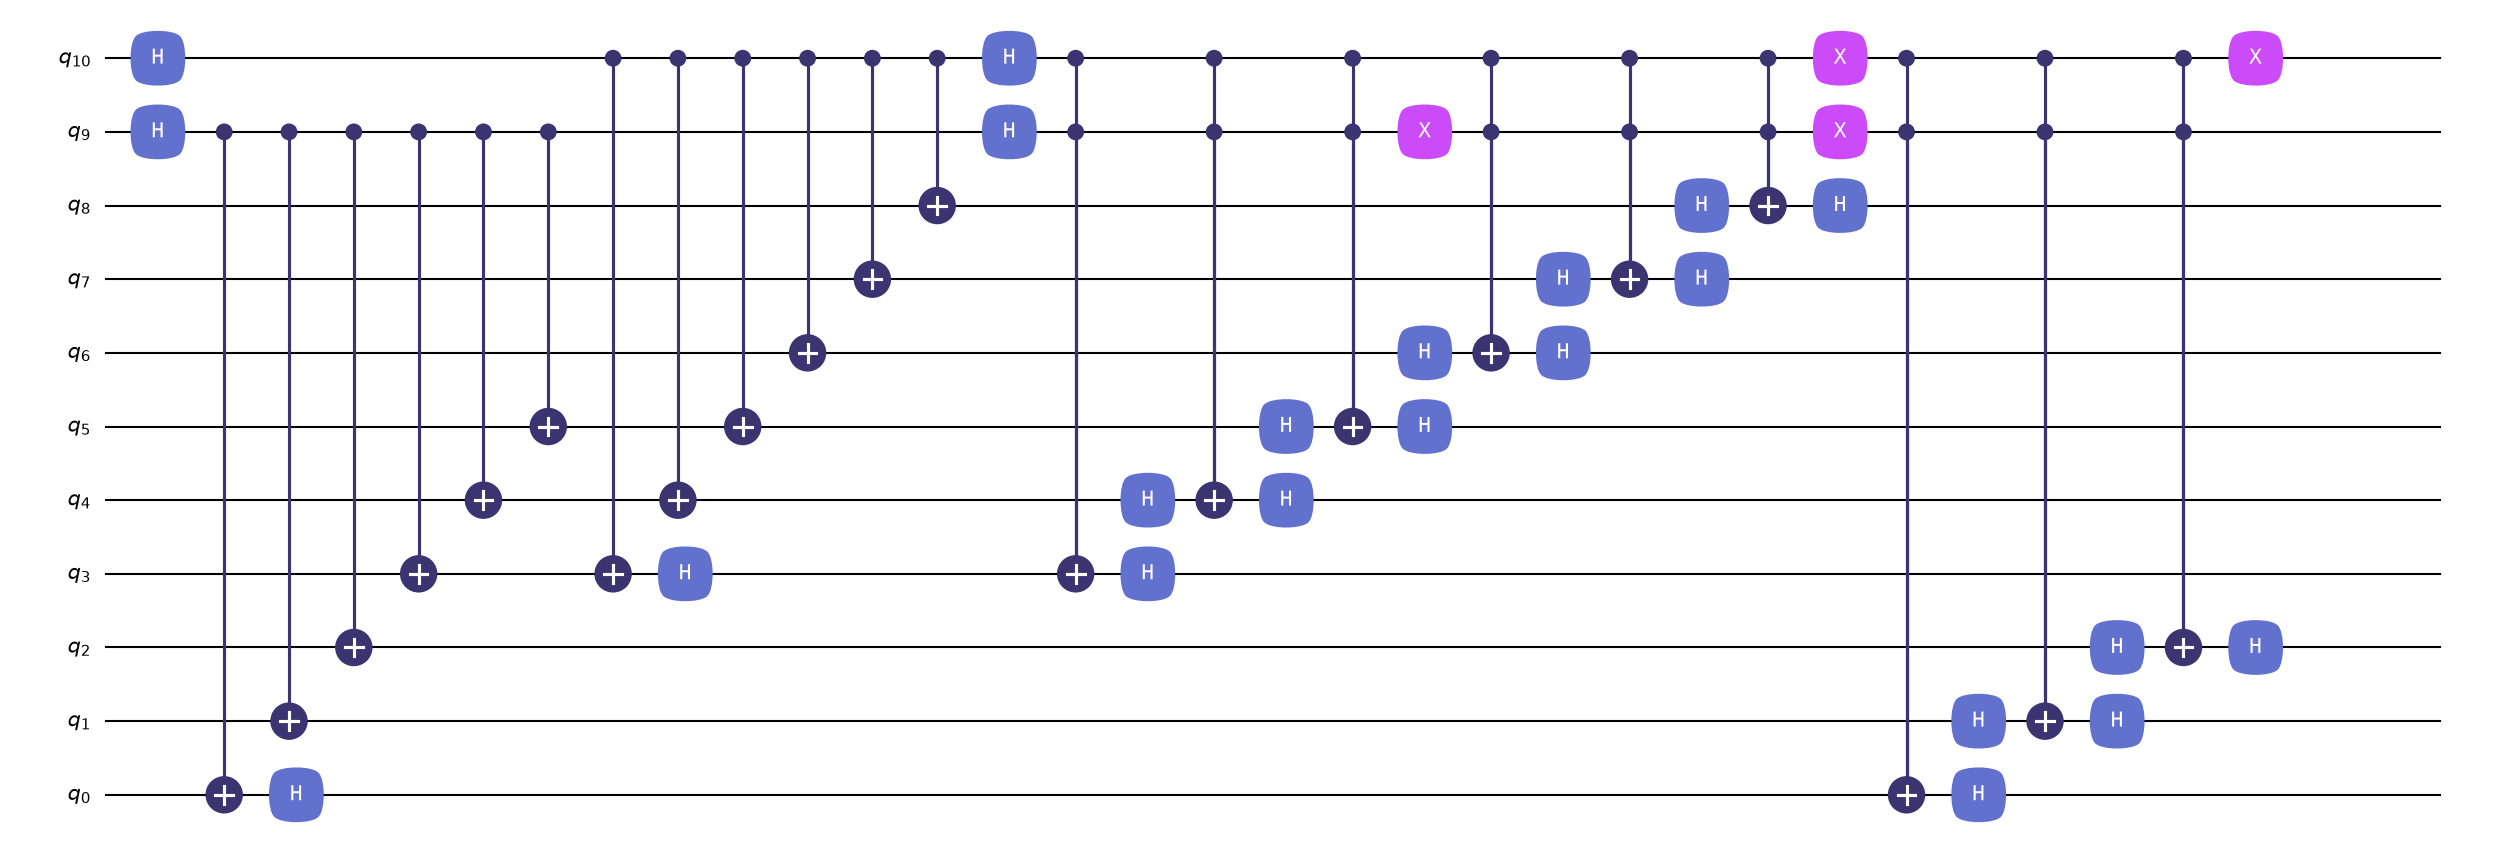

In [ ]:

# CIRCUITO CORRECCION CUANTICA
qcorr = QubitCircuit(11, reverse_states=False)



# Extracción de síndrome
qcorr.add_gate("H", targets=[9])
qcorr.add_gate("H", targets=[10])

for i in range(6):
    qcorr.add_gate("CNOT", controls=[9], targets=[i])

for i in range(6):
    qcorr.add_gate("CNOT", controls=[10], targets=[i+3])

qcorr.add_gate("H", targets=[9])
qcorr.add_gate("H", targets=[10])

# Síndrome 11: corregir bloque 3-5
for k in [3,4,5]:
    qcorr.add_gate("H", targets=[k])
    qcorr.add_gate("TOFFOLI", controls=[9,10], targets=[k])
    qcorr.add_gate("H", targets=[k])

# Síndrome 01: corregir bloque 6-8
qcorr.add_gate("X", targets=[9])

for k in [6,7,8]:
    qcorr.add_gate("H", targets=[k])
    qcorr.add_gate("TOFFOLI", controls=[9,10], targets=[k])
    qcorr.add_gate("H", targets=[k])

qcorr.add_gate("X", targets=[9])

# Síndrome 10: corregir bloque 0-2
qcorr.add_gate("X", targets=[10])

for k in [0,1,2]:
    qcorr.add_gate("H", targets=[k])
    qcorr.add_gate("TOFFOLI", controls=[9,10], targets=[k])
    qcorr.add_gate("H", targets=[k])

qcorr.add_gate("X", targets=[10])



qcorr




In [15]:
#CORRIGE QUANTICAMENTE
quantumcorr=qcorr.run(state=errorstate)
quantumcorr

Quantum object: dims=[[2, 2, 2, 2, 2], [1]], shape=(32, 1), type='ket', dtype=Dense
Qobj data =
[[ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.9486833 ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [-0.31622777]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]]

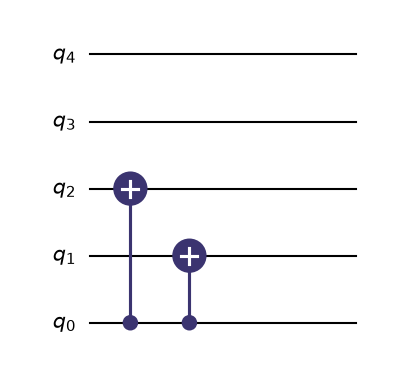

In [16]:
#CIRCUITO DECOD
decod=QubitCircuit(5, reverse_states=False)
decod.add_gate("CNOT", controls=[0], targets=[2])
decod.add_gate("CNOT", controls=[0], targets=[1])
decod


In [17]:
#ELEGIR SI DECODIFICAR EL ESTADO CORREGIDO MANUALMENTE O QUANTICAMENTE (manualcorr, quantumcorr)
decoded_state = decod.run(state=manualcorr)
decoded_state

Quantum object: dims=[[2, 2, 2, 2, 2], [1]], shape=(32, 1), type='ket', dtype=Dense
Qobj data =
[[ 0.9486833 ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [-0.31622777]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]]

In [18]:
decoded_state.ptrace(0).eigenstates()

(array([-2.77555756e-17,  1.00000000e+00]),
 array([Quantum object: dims=[[2], [1]], shape=(2, 1), type='ket', dtype=Dense
        Qobj data =
        [[-0.31622777]
         [-0.9486833 ]]                                                       ,
        Quantum object: dims=[[2], [1]], shape=(2, 1), type='ket', dtype=Dense
        Qobj data =
        [[-0.9486833 ]
         [ 0.31622777]]                                                       ],
       dtype=object))